# Customer churn prediction – Telco

A telecom operator loses about one customer in four. The retention team can only call a limited number of people each month, so the real question is: **who should they call first?**

In this notebook I explore the data, compare a few models and translate the result into something the retention team can use: a ranked list of customers at risk.

Data: IBM Telco Customer Churn sample (7,043 customers, 21 columns).

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA = Path("data/telco_churn.csv")
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, DATA)
IMG = Path("images"); IMG.mkdir(exist_ok=True)

BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
RANDOM_STATE = 42

df = pd.read_csv(DATA)
df.shape

(7043, 21)

## 1. Cleaning

`TotalCharges` is stored as text, and 11 customers have an empty value. They all have `tenure = 0` (they just signed up), so a total of 0 is the correct value, not a missing one.

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["churn"] = (df["Churn"] == "Yes").astype(int)
print(f"Churn rate: {df['churn'].mean():.1%}")

tenure
0    11
Name: count, dtype: int64
Churn rate: 26.5%


## 2. Who leaves?

Before modelling, I look at the churn rate across a few variables the business can act on.

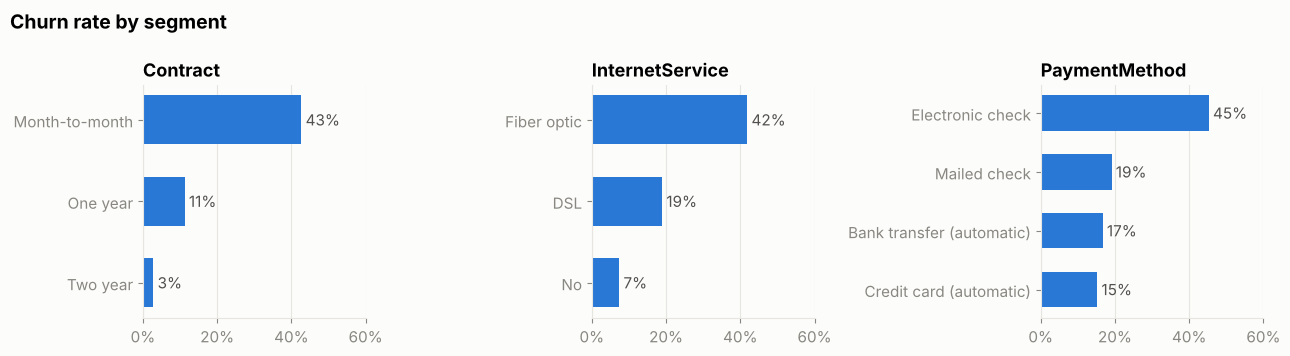

In [3]:
def churn_rate(col):
    return df.groupby(col)["churn"].mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = churn_rate(col)
    bars = ax.barh(r.index, r.values, color=BLUE, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in r.values], padding=3, color="#52514e")
    ax.set_title(col); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 0.6)
fig.suptitle("Churn rate by segment", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); fig.savefig(IMG / "churn_by_segment.png", dpi=150); plt.show()

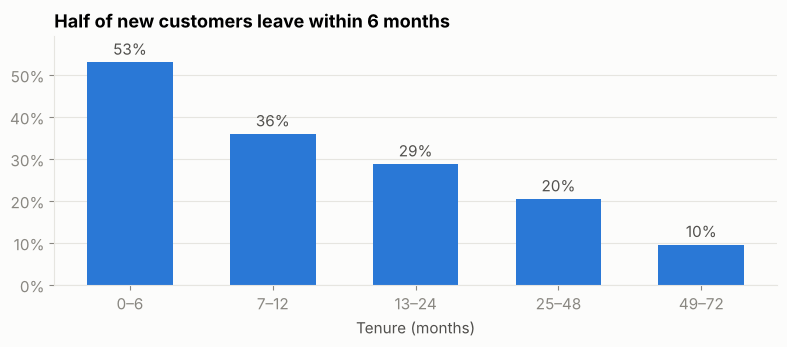

In [4]:
bins = [0, 6, 12, 24, 48, 72]
labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]
t = df.groupby(pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True), observed=True)["churn"].mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(t.index.astype(str), t.values, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in t.values], padding=3, color="#52514e")
ax.set_title("Half of new customers leave within 6 months")
ax.set_xlabel("Tenure (months)"); ax.grid(axis="x", visible=False); ax.margins(y=0.12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
fig.tight_layout(); fig.savefig(IMG / "churn_by_tenure.png", dpi=150); plt.show()

What stands out:

- **Month-to-month contracts** churn at 43%, against 3% for two-year contracts.
- **Fiber optic** customers churn more than DSL customers (42% vs 19%), which is surprising for the premium offer. It may point to a price or quality problem worth investigating.
- **Electronic check** payers churn at 45%, about three times more than automatic payments.
- The **first 6 months** are critical: 53% of these customers leave.

## 3. Modelling

I keep a 20% test set aside and compare three models with 5-fold cross-validation on the training set. The metric is ROC-AUC, because what matters here is **ranking** customers by risk, not a single yes/no decision.

In [5]:
y = df["churn"]
X = df.drop(columns=["customerID", "Churn", "churn"])
numeric = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical = [c for c in X.columns if c not in numeric]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

models = {
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                        max_depth=4, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = {name: cross_val_score(Pipeline([("pre", preprocess), ("model", m)]),
                                X_train, y_train, cv=cv, scoring="roc_auc")
          for name, m in models.items()}
pd.DataFrame({k: [v.mean(), v.std()] for k, v in scores.items()},
             index=["ROC-AUC (mean)", "std"]).T.round(3)

,ROC-AUC (mean),std
Logistic regression,0.846,0.012
Random forest,0.845,0.009
Gradient boosting,0.844,0.009


The three models are **within 0.003 AUC** of each other. The more complex models bring nothing here, so I keep the **logistic regression**: it is just as accurate, faster, and much easier to explain to the business.

In [6]:
model = Pipeline([("pre", preprocess), ("model", models["Logistic regression"])])
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba):.3f}")

Test ROC-AUC: 0.842


## 4. What drives churn?

Permutation importance measures how much the test AUC drops when a variable is shuffled.

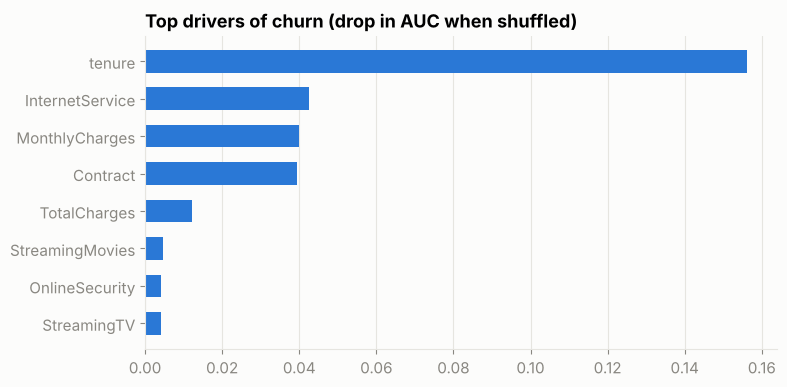

In [7]:
imp = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=RANDOM_STATE)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(8)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_title("Top drivers of churn (drop in AUC when shuffled)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(IMG / "feature_importance.png", dpi=150); plt.show()

## 5. Making it useful: who should the team call?

The model gives each customer a risk score. If the retention team calls the riskiest customers first, how many future churners do they reach?

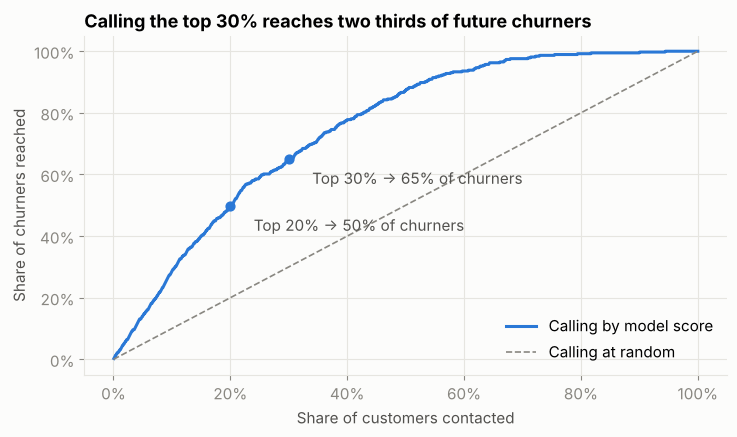

Top 10% contacted -> 28% of churners reached
Top 20% contacted -> 50% of churners reached
Top 30% contacted -> 65% of churners reached


In [8]:
test = pd.DataFrame({"churn": y_test.values, "score": proba}).sort_values("score", ascending=False)
test["share_contacted"] = np.arange(1, len(test) + 1) / len(test)
test["share_churners_reached"] = test["churn"].cumsum() / test["churn"].sum()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(test["share_contacted"], test["share_churners_reached"], color=BLUE, linewidth=2.2,
        label="Calling by model score")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Calling at random")
for k in [0.2, 0.3]:
    reached = test.loc[test["share_contacted"] <= k, "churn"].sum() / test["churn"].sum()
    ax.scatter(k, reached, color=BLUE, s=40, zorder=3)
    ax.annotate(f"Top {k:.0%} → {reached:.0%} of churners", (k, reached),
                xytext=(k + 0.04, reached - 0.08), color="#52514e")
ax.set_title("Calling the top 30% reaches two thirds of future churners")
ax.set_xlabel("Share of customers contacted"); ax.set_ylabel("Share of churners reached")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(IMG / "gain_curve.png", dpi=150); plt.show()

for k in [0.1, 0.2, 0.3]:
    reached = test.loc[test["share_contacted"] <= k, "churn"].sum() / test["churn"].sum()
    print(f"Top {k:.0%} contacted -> {reached:.0%} of churners reached")

## 6. Conclusions

- A simple, explainable model ranks customers well (test AUC around 0.84).
- By calling only the **30% riskiest customers**, the team would reach **about two thirds (65%)** of the people about to leave, against 30% with random calls.
- The strongest levers are **contract type, tenure and internet service**: offering a discount to switch from month-to-month to an annual contract, and onboarding new customers carefully during their first 6 months, are the actions I would test first.
- The fiber optic result deserves a separate look with the product team.

**Limits.** This is a public sample dataset: there is no time dimension, so I can't check whether the model holds over time. In production I would retrain monthly and measure the real impact of retention calls with an A/B test.